*Author:*  
Manuel Eugenio Morocho Cayamcela, PhD

# Clasificacion de causas de divorcio con una red neuronal Keras

Entrena y evalua un clasificador multiclase con los registros ecuatorianos de divorcios de 2025.

## Objetivos de aprendizaje

- Preparar variables demogr?ficas y del matrimonio para el modelado.
- Entrenar una red neuronal Keras para clasificar la causa del divorcio.
- Evaluar las predicciones considerando el desequilibrio entre clases.

La variable objetivo, `cau_div`, describe la causa del divorcio.

## Contenido

## 1. Load and inspect the data

Carga `EDV_2025.csv`, delimitado por punto y coma, e inspecciona sus primeras filas.


In [82]:
%pip install -q pandas matplotlib seaborn scikit-learn tensorflow keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import tensorflow as tf

#SEED = 42
#tf.keras.utils.set_random_seed(SEED)

In [85]:
data_path = Path(r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 9\EDV_2025.csv")
divorces_df = pd.read_csv(data_path, sep=";", encoding="utf-8-sig", low_memory=False)
print("Dimensiones:", divorces_df.shape)
divorces_df.head()

Dimensiones: (24991, 50)


,prov_insc,cant_insc,parr_insc,anio_insc,mes_insc,dia_insc,fecha_insc,anio_div,mes_div,dia_div,...,fecha_nac2,edad_2,hijos_2,p_etnica2,niv_inst2,sabe_leer2,prov_hab2,cant_hab2,parr_hab2,area_2
0,Azuay,Cuenca,Bellavista,2025,Enero,30,1/30/2025,2024,Junio,19,...,1974/09/18,50,0,Mestiza,Secundaria,Si,Azuay,Cuenca,Monay,Urbana
1,Azuay,Cuenca,Bellavista,2025,Enero,31,1/31/2025,2024,Mayo,7,...,1997/09/30,27,1,Mestiza,Educación media / Bachillerato,Si,Azuay,Cuenca,Bellavista,Urbana
2,Azuay,Cuenca,Bellavista,2025,Enero,10,1/10/2025,2025,Enero,6,...,1992/12/28,32,2,Mestiza,Secundaria,Si,Azuay,Sigsig,"Sigsig, cabecera cantonal",Urbana
3,Azuay,Cuenca,Bellavista,2025,Enero,7,1/7/2025,2012,Julio,28,...,1978/06/20,46,0,Mestiza,Secundaria,Si,Azuay,Cuenca,"Cuenca, cabecera cantonal y capital provincial",Urbana
4,El Oro,Machala,Machala,2025,Abril,3,4/3/2025,2025,Marzo,17,...,1990/07/16,34,1,Mestiza,Educación media / Bachillerato,Si,El Oro,Machala,Machala,Urbana


C:\Users\Usuario\AppData\Local\Temp\ipykernel_16236\2277758327.py:3: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout();


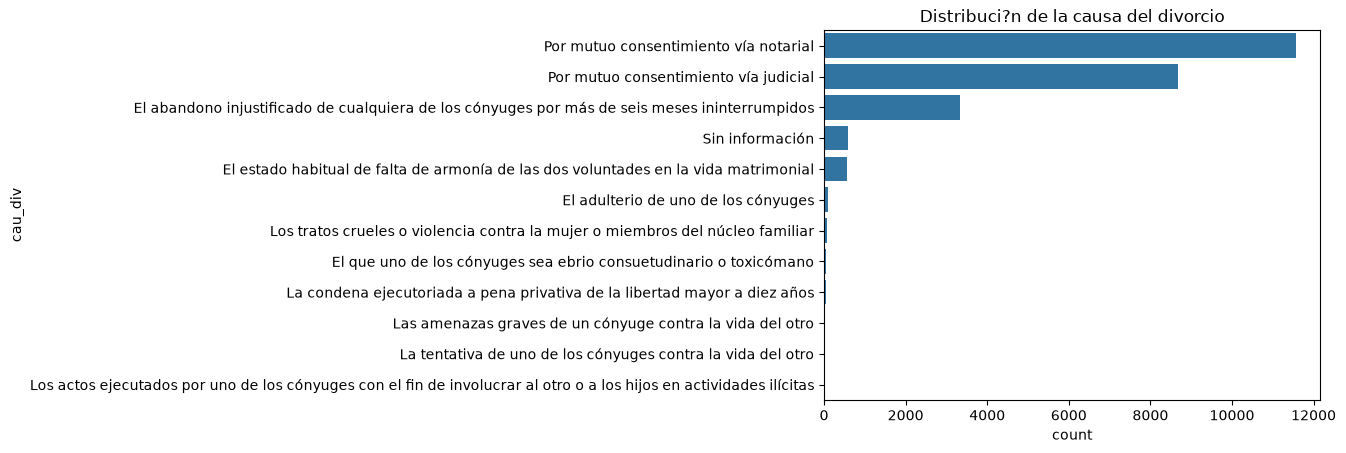

In [86]:
sns.countplot(data=divorces_df, y="cau_div", order=divorces_df["cau_div"].value_counts().index)
plt.title("Distribuci?n de la causa del divorcio")
plt.tight_layout();

**Variables predictoras seleccionadas:** duraci?n del matrimonio, edades y n?mero de hijos de ambos c?nyuges, a?o del matrimonio, provincia de inscripci?n, nivel de instrucci?n, autoidentificaci?n ?tnica y ?rea de residencia.

La distribuci?n de `cau_div` permite observar el fuerte desequilibrio entre algunas causas frecuentes y otras poco representadas.

## 2. Prepare the data

Inspect data types and missing values.

In [87]:
divorces_df.info()
divorces_df.isna().sum().sort_values(ascending=False).head(10)

<class 'pandas.DataFrame'>
RangeIndex: 24991 entries, 0 to 24990
Data columns (total 50 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   prov_insc   24991 non-null  str  
 1   cant_insc   24991 non-null  str  
 2   parr_insc   24991 non-null  str  
 3   anio_insc   24991 non-null  int64
 4   mes_insc    24991 non-null  str  
 5   dia_insc    24991 non-null  int64
 6   fecha_insc  24991 non-null  str  
 7   anio_div    24991 non-null  int64
 8   mes_div     24991 non-null  str  
 9   dia_div     24991 non-null  int64
 10  fecha_div   24991 non-null  str  
 11  anio_mat    24991 non-null  int64
 12  mes_mat     24991 non-null  str  
 13  dia_mat     24991 non-null  int64
 14  fecha_mat   24991 non-null  str  
 15  mcap_bie    24991 non-null  str  
 16  dur_mat     24991 non-null  int64
 17  cau_div     24991 non-null  str  
 18  nac_1       24991 non-null  str  
 19  cod_pais1   24991 non-null  str  
 20  sexo_1      24991 non-null  str  
 21  

prov_insc     0
cant_insc     0
parr_insc     0
anio_insc     0
mes_insc      0
dia_insc      0
fecha_insc    0
anio_div      0
mes_div       0
dia_div       0
dtype: int64

#### Outliers

##### Plot the value range of each column

El diagrama de caja permite revisar los rangos de las variables num?ricas seleccionadas.

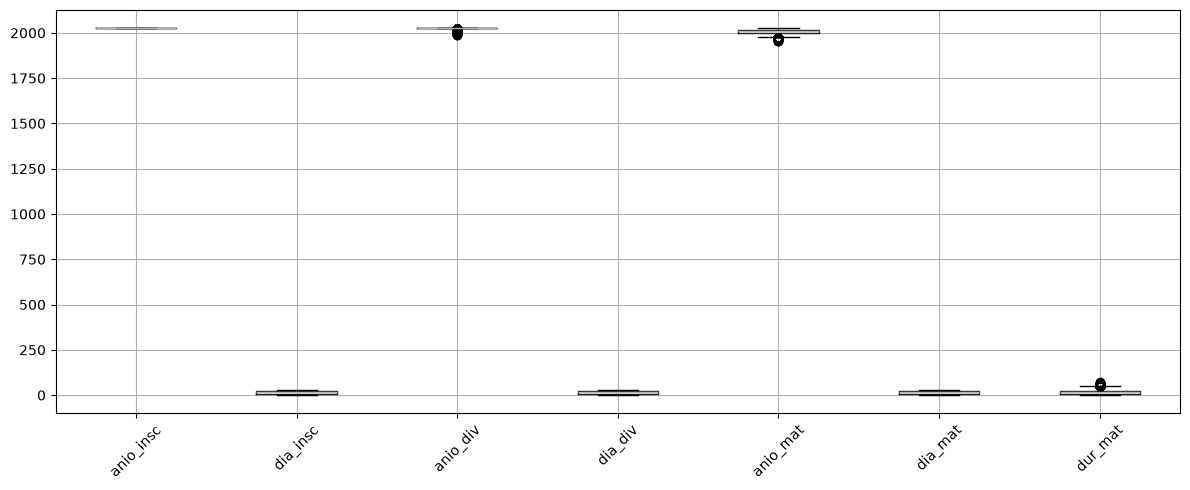

In [88]:
numeric_data = divorces_df.select_dtypes(include="number")
fig, ax = plt.subplots(figsize=(12, 5))
numeric_data.boxplot(ax=ax)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conservamos los valores extremos en esta actividad. La imputaci?n de valores num?ricos faltantes se calcular? solo con los datos de entrenamiento para evitar fuga de informaci?n.

#### Convertir y limpiar variables num?ricas

Algunas columnas num?ricas, como edades y n?mero de hijos, vienen como texto y pueden incluir valores como `Sin informaci?n`. Se convertir?n a n?meros; los valores no interpretables se tratar?n como faltantes.

In [89]:
numeric_features = ["dur_mat", "edad_1", "edad_2", "hijos_1", "hijos_2", "anio_mat"]
categorical_features = [
    "prov_insc", "niv_inst1", "niv_inst2", "p_etnica1", "p_etnica2", "area_1", "area_2"
]
model_df = divorces_df[numeric_features + categorical_features + ["cau_div"]].copy()

for column in numeric_features:
    model_df[column] = pd.to_numeric(model_df[column], errors="coerce")
model_df[categorical_features] = model_df[categorical_features].fillna("Sin informaci?n").astype(str)
model_df = model_df.dropna(subset=["cau_div"])
model_df.head()

,dur_mat,edad_1,edad_2,hijos_1,hijos_2,anio_mat,prov_insc,niv_inst1,niv_inst2,p_etnica1,p_etnica2,area_1,area_2,cau_div
0,25,52.0,50.0,0.0,0.0,1998,Azuay,Secundaria,Secundaria,Mestizo,Mestiza,Urbana,Urbana,Por mutuo consentimiento vía judicial
1,3,31.0,27.0,0.0,1.0,2020,Azuay,Educación media / Bachillerato,Educación media / Bachillerato,Mestizo,Mestiza,Urbana,Urbana,Por mutuo consentimiento vía judicial
2,7,37.0,32.0,0.0,2.0,2017,Azuay,Secundaria,Secundaria,Mestizo,Mestiza,Urbana,Urbana,Por mutuo consentimiento vía notarial
3,6,50.0,46.0,0.0,0.0,2006,Azuay,Educación media / Bachillerato,Secundaria,Mestizo,Mestiza,Urbana,Urbana,Por mutuo consentimiento vía notarial
4,15,34.0,34.0,0.0,1.0,2009,El Oro,Educación media / Bachillerato,Educación media / Bachillerato,Mestizo,Mestiza,Urbana,Urbana,Por mutuo consentimiento vía notarial


#### Revisar los valores faltantes

Se revisan los faltantes despu?s de convertir las columnas. Las variables num?ricas se imputar?n con medianas calculadas a partir del conjunto de entrenamiento.

In [90]:
model_df[numeric_features].isna().sum()

dur_mat        0
edad_1         8
edad_2         3
hijos_1     1734
hijos_2     1291
anio_mat       0
dtype: int64

#### Correlaciones entre variables num?ricas

La matriz de correlaci?n se calcula ?nicamente con las variables num?ricas seleccionadas.

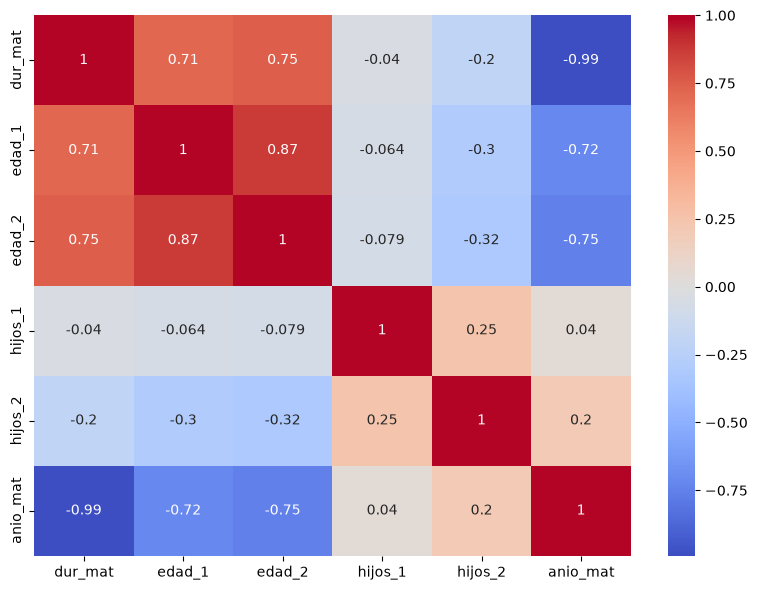

In [91]:
plt.figure(figsize=(8, 6))
sns.heatmap(model_df[numeric_features].corr(), annot=True, cmap="coolwarm", center=0)
plt.tight_layout();

La correlaci?n describe relaciones lineales entre variables num?ricas; no implica causalidad. Las variables categ?ricas se codificar?n por separado para el modelo.

#### Separar las variables predictoras `X` y el objetivo `y`

Las variables seleccionadas se usan como predictores; `cau_div` ser? la clase que se intenta predecir.

In [92]:
X_raw = model_df[numeric_features + categorical_features].copy()
X_raw.head()

,dur_mat,edad_1,edad_2,hijos_1,hijos_2,anio_mat,prov_insc,niv_inst1,niv_inst2,p_etnica1,p_etnica2,area_1,area_2
0,25,52.0,50.0,0.0,0.0,1998,Azuay,Secundaria,Secundaria,Mestizo,Mestiza,Urbana,Urbana
1,3,31.0,27.0,0.0,1.0,2020,Azuay,Educación media / Bachillerato,Educación media / Bachillerato,Mestizo,Mestiza,Urbana,Urbana
2,7,37.0,32.0,0.0,2.0,2017,Azuay,Secundaria,Secundaria,Mestizo,Mestiza,Urbana,Urbana
3,6,50.0,46.0,0.0,0.0,2006,Azuay,Educación media / Bachillerato,Secundaria,Mestizo,Mestiza,Urbana,Urbana
4,15,34.0,34.0,0.0,1.0,2009,El Oro,Educación media / Bachillerato,Educación media / Bachillerato,Mestizo,Mestiza,Urbana,Urbana


Keras requiere etiquetas num?ricas consecutivas para la clasificaci?n multiclase. `LabelEncoder` conserva el mapeo entre cada n?mero y su causa original.

In [93]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(model_df["cau_div"])
pd.Series(label_encoder.classes_, name="causa")

0     El abandono injustificado de cualquiera de los...
1                   El adulterio de uno de los cónyuges
2     El estado habitual de falta de armonía de las ...
3     El que uno de los cónyuges sea ebrio consuetud...
4     La condena ejecutoriada a pena privativa de la...
5     La tentativa de uno de los cónyuges contra la ...
6     Las amenazas graves de un cónyuge contra la vi...
7     Los actos ejecutados por uno de los cónyuges c...
8     Los tratos crueles o violencia contra la mujer...
9                 Por mutuo consentimiento vía judicial
10                Por mutuo consentimiento vía notarial
11                                      Sin información
Name: causa, dtype: str

#### Split the data into training and test sets

Se reserva el 30% para la prueba final. Del resto se separa la validaci?n por clase, garantizando que incluso las causas poco frecuentes est?n presentes en entrenamiento y validaci?n.

In [94]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_full, X_test_raw, y_train_full, y_test = train_test_split(
    X_raw, y, test_size=0.3, stratify=y, random_state=42
)

rng = np.random.RandomState(42)
train_indices, val_indices = [], []
for class_id in np.unique(y_train_full):
    class_indices = np.flatnonzero(y_train_full == class_id)
    rng.shuffle(class_indices)
    validation_count = min(max(1, round(0.2 * len(class_indices))), len(class_indices) - 1)
    val_indices.extend(class_indices[:validation_count])
    train_indices.extend(class_indices[validation_count:])

X_train_raw = X_train_full.iloc[train_indices]
X_val_raw = X_train_full.iloc[val_indices]
y_train = y_train_full[train_indices]
y_val = y_train_full[val_indices]

X_train = pd.get_dummies(X_train_raw, columns=categorical_features)
X_val = pd.get_dummies(X_val_raw, columns=categorical_features).reindex(
    columns=X_train.columns, fill_value=0
)
X_test = pd.get_dummies(X_test_raw, columns=categorical_features).reindex(
    columns=X_train.columns, fill_value=0
)

train_medians = X_train[numeric_features].median()
X_train[numeric_features] = X_train[numeric_features].fillna(train_medians)
X_val[numeric_features] = X_val[numeric_features].fillna(train_medians)
X_test[numeric_features] = X_test[numeric_features].fillna(train_medians)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("Entrenamiento:", X_train.shape, "Validaci?n:", X_val.shape, "Prueba:", X_test.shape)

Entrenamiento: (13993, 72) Validaci?n: (3500, 72) Prueba: (7498, 72)


## 3. Construir y entrenar la red neuronal

La capa final usa `softmax` para producir probabilidades sobre las causas de divorcio.

TensorFlow y scikit-learn se instalan en la celda de preparaci?n. TensorFlow proporciona la API Keras para construir la red neuronal.

#### Define a simple neural network

Import `Sequential` to stack layers and `Dense` to create fully connected layers.

In [95]:
# Import the modules used to build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

La red tiene dos capas ocultas con activaci?n ReLU. La capa de salida contiene una unidad por cada clase y usa `softmax`.

In [96]:
# To define the input shape of the model, we need to know the number of features in the training data. The shape of X_train is (number of samples, number of features). By accessing X_train.shape[1], we get the number of features, which will be used as the input dimension for the first layer of the neural network.
X_train.shape[1] 

72

In [97]:
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(len(label_encoder.classes_), activation="softmax"),
])

#### Compile the neural network

Se utiliza `sparse_categorical_crossentropy`, adecuada para varias clases con etiquetas enteras, y exactitud como m?trica b?sica.

In [98]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

#### Inspect the neural-network summary

`model.summary()` displays each layer, its output shape, and its trainable parameters.

In [99]:
# Display the model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 12)             │           204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,068 (11.98 KB)

 Trainable params: 3,068 (11.98 KB)

 Non-trainable params: 0 (0.00 B)

In [100]:
# Display the model output shape
model.output_shape

(None, 12)

#### Train the neural network

`model.fit()` learns from the training examples. An epoch is one pass through the training set; `batch_size` controls how many examples are processed before each weight update.

#### Train with early stopping to reduce overfitting

In [101]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    ),
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4917 - loss: 1.3568 - val_accuracy: 0.5383 - val_loss: 1.1544
Epoch 2/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5420 - loss: 1.1370 - val_accuracy: 0.5543 - val_loss: 1.1300
Epoch 3/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5476 - loss: 1.1126 - val_accuracy: 0.5531 - val_loss: 1.1194
Epoch 4/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5537 - loss: 1.0976 - val_accuracy: 0.5603 - val_loss: 1.1120
Epoch 5/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5555 - loss: 1.0889 - val_accuracy: 0.5566 - val_loss: 1.1133
Epoch 6/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5565 - loss: 1.0822 - val_accuracy: 0.5523 - val_loss: 1.1130
Epoch 7/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5561 - loss: 1.0746 - val_accuracy: 0.5554 - val_loss: 1.1111
Epoch 8/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5610 - loss: 1.0688 - val_accu

#### Visualizar las curvas de aprendizaje

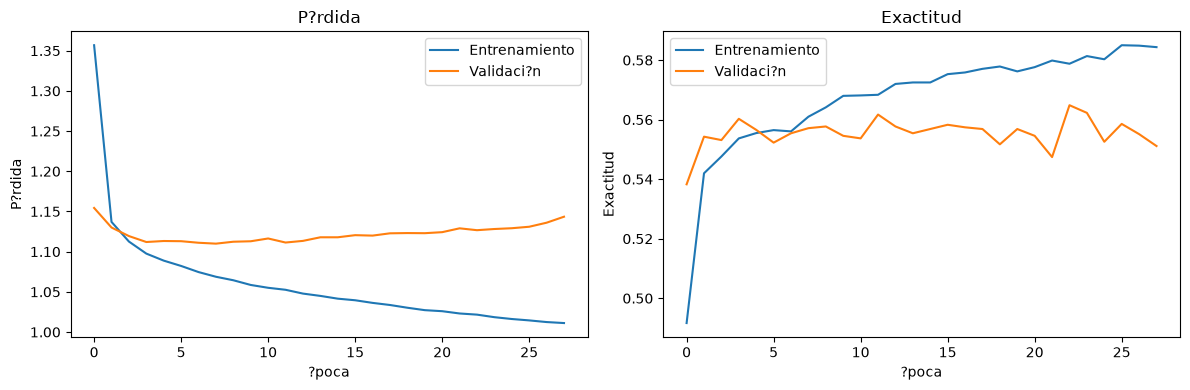

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Entrenamiento")
axes[0].plot(history.history["val_loss"], label="Validaci?n")
axes[0].set(title="P?rdida", xlabel="?poca", ylabel="P?rdida")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Entrenamiento")
axes[1].plot(history.history["val_accuracy"], label="Validaci?n")
axes[1].set(title="Exactitud", xlabel="?poca", ylabel="Exactitud")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Evaluate the model

Se comparan las m?tricas de entrenamiento y prueba. El reporte por clase y el F1 macro ayudan a interpretar resultados cuando las clases est?n desequilibradas.

In [103]:
from sklearn.metrics import classification_report, f1_score

train_scores = model.evaluate(X_train, y_train, verbose=False)
test_scores = model.evaluate(X_test, y_test, verbose=False)
baseline_test_accuracy = test_scores[1]
print(f"Exactitud de entrenamiento: {train_scores[1]:.2%}")
print(f"Exactitud de prueba (modelo base): {baseline_test_accuracy:.2%}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
baseline_test_macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print(f"F1 macro de prueba (modelo base): {baseline_test_macro_f1:.3f}")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0,
))

Exactitud de entrenamiento: 57.00%
Exactitud de prueba (modelo base): 53.99%
F1 macro de prueba (modelo base): 0.113
                                                                                                                     precision    recall  f1-score   support

                      El abandono injustificado de cualquiera de los cónyuges por más de seis meses ininterrumpidos       0.36      0.13      0.19       998
                                                                                El adulterio de uno de los cónyuges       0.00      0.00      0.00        27
                                El estado habitual de falta de armonía de las dos voluntades en la vida matrimonial       0.00      0.00      0.00       168
                                                  El que uno de los cónyuges sea ebrio consuetudinario o toxicómano       0.00      0.00      0.00        14
                                          La condena ejecutoriada a pena privativa de la libertad

## 5. Realizar una predicci?n

Selecciona un registro del conjunto de prueba para revisar la clase predicha.

In [104]:
persona_de_prueba = X_test.iloc[0]
persona_de_prueba

dur_mat                      0.641571
edad_1                       0.150852
edad_2                       0.312779
hijos_1                     -0.259981
hijos_2                      0.373522
                               ...   
p_etnica2_Sin información   -0.120416
area_1_Rural                -0.400352
area_1_Urbana                0.400352
area_2_Rural                -0.406460
area_2_Urbana                0.406460
Name: 16342, Length: 72, dtype: float64

Keras espera una matriz bidimensional: una fila por ejemplo y una columna por variable predictora.

In [105]:
prediccion = model.predict(persona_de_prueba.to_frame().T, verbose=0)
prediccion

array([[3.2179463e-01, 3.0213504e-03, 9.9539226e-03, 4.7464864e-03,
        2.5498637e-03, 6.3354592e-04, 1.1629474e-03, 1.4959979e-04,
        3.9665303e-03, 2.5477743e-01, 3.8380289e-01, 1.3440774e-02]],
      dtype=float32)

La clase predicha corresponde a la probabilidad `softmax` m?s alta. Se compara con la causa real del registro de prueba.

In [106]:
clase_predicha = label_encoder.inverse_transform([prediccion.argmax(axis=1)[0]])[0]
clase_real = label_encoder.inverse_transform([int(y_test[0])])[0]
print("Causa predicha:", clase_predicha)
print("Causa real:", clase_real)

Causa predicha: Por mutuo consentimiento vía notarial
Causa real: Por mutuo consentimiento vía judicial


## 6. Save and reload the model

In [107]:
model.save('modelo_cau_div.keras')

In [108]:
from tensorflow.keras.models import load_model

modelo_cargado = load_model("modelo_cau_div.keras")

In [109]:
probabilidades_cargadas = modelo_cargado.predict(persona_de_prueba.to_frame().T, verbose=0)
clase_cargada = label_encoder.inverse_transform([probabilidades_cargadas.argmax(axis=1)[0]])[0]
print("Predicci?n del modelo recargado:", clase_cargada)

Predicci?n del modelo recargado: Por mutuo consentimiento vía notarial


## Actividad: optimizar la arquitectura de la red neuronal

### Objetivo
Mejorar el clasificador multiclase de `cau_div` mediante b?squeda de hiperpar?metros.

### Instrucciones

1. Trabaja en grupo o individualmente.
2. Prueba `keras-tuner` u `optuna` para buscar hiperpar?metros.
3. Eval?a el mejor modelo con exactitud y m?tricas por clase, incluido F1 macro.
4. Compara los resultados con el modelo inicial y comenta las limitaciones de las clases poco frecuentes.

## 7. Optimizacion de hiperparametros con Keras Tuner

Se usa busqueda aleatoria para explorar numero de capas, unidades, dropout, tasa de aprendizaje y tamano de lote. El objetivo es maximizar el F1 macro de validacion, porque las causas estan desbalanceadas. El conjunto de prueba se reserva para la comparacion final.

In [110]:
import keras_tuner as kt

num_classes = len(label_encoder.classes_)
y_train_tuner = tf.keras.utils.to_categorical(y_train, num_classes=num_classes)
y_val_tuner = tf.keras.utils.to_categorical(y_val, num_classes=num_classes)

class DivorceHyperModel(kt.HyperModel):
    def build(self, hp):
        tuned_model = Sequential()
        tuned_model.add(tf.keras.Input(shape=(X_train.shape[1],)))

        num_layers = hp.Int("num_layers", min_value=1, max_value=3)
        dropout_rate = hp.Choice("dropout_rate", values=[0.0, 0.2, 0.4])
        for layer_index in range(num_layers):
            units = hp.Choice(f"units_{layer_index + 1}", values=[16, 32, 64])
            tuned_model.add(Dense(units, activation="relu"))
            tuned_model.add(tf.keras.layers.Dropout(dropout_rate))

        learning_rate = hp.Choice("learning_rate", values=[1e-4, 5e-4, 1e-3])
        tuned_model.add(Dense(num_classes, activation="softmax"))
        tuned_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
            loss="categorical_crossentropy",
            metrics=[
                "accuracy",
                tf.keras.metrics.F1Score(
                    average="macro", threshold=None, name="macro_f1"
                ),
            ],
        )
        return tuned_model

    def fit(self, hp, tuned_model, *args, **kwargs):
        kwargs["batch_size"] = hp.Choice("batch_size", values=[32, 64])
        return tuned_model.fit(*args, **kwargs)


hyperparameter_search = kt.RandomSearch(
    hypermodel=DivorceHyperModel(),
    objective=kt.Objective("val_macro_f1", direction="max"),
    max_trials=8,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="cau_div",
    overwrite=True,
    seed=42,
)

hyperparameter_search.search(
    X_train,
    y_train_tuner,
    validation_data=(X_val, y_val_tuner),
    epochs=80,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=8,
            restore_best_weights=True,
        )
    ],
    verbose=1,
)

best_hyperparameters = hyperparameter_search.get_best_hyperparameters(num_trials=1)[0]
print("Mejores hiperparametros:", best_hyperparameters.values)

Trial 8 Complete [00h 00m 50s]
val_macro_f1: 0.10913550853729248

Best val_macro_f1 So Far: 0.12829463183879852
Total elapsed time: 00h 05m 07s
Mejores hiperparametros: {'num_layers': 1, 'dropout_rate': 0.0, 'units_1': 32, 'learning_rate': 0.001, 'units_2': 32, 'batch_size': 32, 'units_3': 32}


In [111]:
from sklearn.metrics import classification_report

best_model = hyperparameter_search.get_best_models(num_models=1)[0]
best_test_metrics = best_model.evaluate(
    X_test,
    tf.keras.utils.to_categorical(y_test, num_classes=num_classes),
    return_dict=True,
    verbose=0,
)
y_pred_tuned = best_model.predict(X_test, verbose=0).argmax(axis=1)
tuned_test_macro_f1 = f1_score(y_test, y_pred_tuned, average="macro", zero_division=0)

tuned_test_accuracy = best_test_metrics["accuracy"]
print(f"Exactitud de prueba (modelo base): {baseline_test_accuracy:.2%}")
print(f"Exactitud de prueba (modelo optimizado): {tuned_test_accuracy:.2%}")
print(f"F1 macro de prueba (modelo base): {baseline_test_macro_f1:.3f}")
print(f"F1 macro de prueba (modelo optimizado): {tuned_test_macro_f1:.3f}")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=range(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0,
))

c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


Exactitud de prueba (modelo base): 53.99%
Exactitud de prueba (modelo optimizado): 56.23%
F1 macro de prueba (modelo base): 0.113
F1 macro de prueba (modelo optimizado): 0.145
                                                                                                                     precision    recall  f1-score   support

                      El abandono injustificado de cualquiera de los cónyuges por más de seis meses ininterrumpidos       0.39      0.17      0.24       998
                                                                                El adulterio de uno de los cónyuges       0.00      0.00      0.00        27
                                El estado habitual de falta de armonía de las dos voluntades en la vida matrimonial       0.32      0.06      0.10       168
                                                  El que uno de los cónyuges sea ebrio consuetudinario o toxicómano       1.00      0.07      0.13        14
                                      

a. Which hyperparameter search method did you use?
Utilicé búsqueda aleatoria con Keras Tuner (RandomSearch), con 8 pruebas y el objetivo de maximizar el F1 macro en el conjunto de validación. Se aplicó detención temprana para evitar entrenamientos innecesarios

b. Which parameters did you search?
Se probaron entre 1 y 3 capas ocultas, con 16, 32 o 64 neuronas por capa; dropout de 0, 0,2 o 0,4; tasas de aprendizaje de 0,0001, 0,0005 o 0,001; y tamaños de lote de 32 o 64. La mejor configuración encontrada fue 1 capa oculta con 32 neuronas, dropout 0, tasa de aprendizaje 0,001 y tamaño de lote 32.

c. How do the optimized network metrics compare with the baseline network?
En el conjunto de prueba, el modelo base obtuvo 53,99 % de exactitud y 0,113 de F1 macro. El modelo optimizado obtuvo 56,23 % de exactitud y 0,145 de F1 macro. El F1 ponderado pasó de 0,50 a 0,53. Aunque hubo una mejora, el F1 macro sigue siendo bajo, especialmente para las causas poco frecuentes

d. What else would you try to improve the metrics or reduce overfitting?
Intentaría obtener más ejemplos de las causas menos frecuentes y probar ponderación de clases o una función de pérdida focal. También evaluaría regularización L2, otras variables predictoras y validación cruzada estratificada. Mantendría el conjunto de prueba separado para la evaluación final